# Simulador Socioeconômico — Versão Corrigida

Este notebook reúne todos os módulos do simulador com as correções aplicadas:
- **`demografia.py`**: Sincronização da população total (`criancas + adultos + idosos`).
- **`config.py`**: Parâmetros globais centralizados e integrados aos módulos.
- **`economia.py`**: Oferta de vagas vinculada às empresas e ao capital, evitando desemprego 0% crônico.
- **`indicadores.py`**: Saúde, educação e inovação evoluindo conforme o investimento público per capita.
- **`comercio.py`**: Limpeza de linhas mortas e resíduos de refatoração.
- **`main.py`**: Verificação não-bloqueante compatível com Windows, Linux e Google Colab.

# **config**

In [66]:
%%writefile config.py
# Parâmetros Globais do Simulador
ANOS_GERADOR = 100
POPULACAO_INICIAL = 10000
PROPORCAO_CRIANCAS = 0.25
PROPORCAO_ADULTOS = 0.60
PROPORCAO_IDOSOS = 0.15

PIB_INICIAL = 100_000_000.0
CAPITAL_INICIAL = 50_000_000.0
EMPRESAS_INICIAIS = 250

ALIMENTOS_INICIAIS = 50000.0
ENERGIA_INICIAL = 40000.0
MINERIO_INICIAL = 30000.0

VAGAS_POR_EMPRESA = 22
SALARIO_MINIMO = 1400.0
SALARIO_BASE = 2500.0
GASTO_SOCIAL_IDEAL = 1500.0
EXPECTATIVA_VIDA_BASE = 65
PRECO_BASE_ALIMENTO = 10.0

Writing config.py


In [67]:
%%writefile demografia.py
def atualizar_demografia(ilha):
    """Atualiza faixas etárias e recalcula a população total corretamente."""
    taxa_natalidade = 0.018 * (0.5 + ilha.saude * 0.5)
    taxa_mortalidade_infantil = 0.005 * (1.2 - ilha.saude)
    taxa_mortalidade_adulta = 0.006 * (1.2 - ilha.saude)
    taxa_mortalidade_idosa = 0.045 * (1.3 - ilha.saude)

    nascimentos = int(ilha.adultos * taxa_natalidade)
    mortes_criancas = int(ilha.criancas * taxa_mortalidade_infantil)
    mortes_adultos = int(ilha.adultos * taxa_mortalidade_adulta)
    mortes_idosos = int(ilha.idosos * taxa_mortalidade_idosa)

    # Transição etária anual
    novos_adultos = int(ilha.criancas * (1 / 18))
    novos_idosos = int(ilha.adultos * (1 / 45))

    ilha.criancas = max(0, ilha.criancas + nascimentos - mortes_criancas - novos_adultos)
    ilha.adultos = max(0, ilha.adultos + novos_adultos - mortes_adultos - novos_idosos)
    ilha.idosos = max(0, ilha.idosos + novos_idosos - mortes_idosos)

    # Correção crítica: população total sempre sincronizada
    ilha.populacao = ilha.criancas + ilha.adultos + ilha.idosos

Overwriting demografia.py


In [68]:
%%writefile economia.py
import config

def atualizar_economia(ilha):
    """Calcula produtividade, mercado de trabalho realista, PIB e formação de capital."""
    ilha.produtividade = 1.0 + (ilha.educacao * 0.8) + (ilha.inovacao * 1.2)

    # Capacidade real de geração de vagas vinculada às empresas e capital
    fator_capital = min(1.5, ilha.capital / max(1.0, ilha.pib * 0.5))
    vagas_potenciais = int(ilha.empresas * config.VAGAS_POR_EMPRESA * fator_capital)
    teto_emprego = int(ilha.adultos * 0.96)  # Desemprego friccional mínimo de ~4%
    ilha.vagas_formais = min(teto_emprego, max(0, vagas_potenciais))

    desempregados = max(0, ilha.adultos - ilha.vagas_formais)
    ilha.taxa_desemprego = desempregados / max(1, ilha.adultos)

    ilha.salario_medio = max(config.SALARIO_MINIMO, config.SALARIO_BASE * ilha.produtividade)
    ilha.massa_salarial = ilha.vagas_formais * ilha.salario_medio * 12

    # PIB impulsionado por massa salarial, produção e capital
    producao_industrial = ilha.empresas * 150000.0 * ilha.produtividade
    ilha.pib = max(1_000_000.0, ilha.massa_salarial + producao_industrial)

    # Investimento privado e depreciação
    investimento = ilha.pib * 0.12 * (1.0 - ilha.taxa_juros)
    depreciacao = ilha.capital * 0.05
    ilha.capital = max(1_000_000.0, ilha.capital + investimento - depreciacao)

    # Dinâmica de abertura/fechamento de empresas
    if ilha.taxa_juros < 0.12 and ilha.pib > ilha.pib_anterior:
        ilha.empresas += max(1, int(ilha.empresas * 0.02))
    elif ilha.taxa_desemprego > 0.20:
        ilha.empresas = max(10, int(ilha.empresas * 0.98))

Overwriting economia.py


In [69]:
%%writefile recursos.py
def atualizar_recursos(ilha):
    """Modela produção, consumo e regeneração de recursos naturais."""
    producao_alimentos = ilha.adultos * 2.2 * (0.8 + ilha.inovacao * 0.5)
    consumo_alimentos = ilha.populacao * 1.1
    ilha.consumo_alimentos = consumo_alimentos
    ilha.recursos_alimentos = max(0.0, ilha.recursos_alimentos + producao_alimentos - consumo_alimentos)

    consumo_energia = ilha.empresas * 45.0 + ilha.populacao * 0.5
    geracao_energia = 35000.0 * (1.0 + ilha.inovacao * 0.4)
    ilha.recursos_energia = max(0.0, ilha.recursos_energia + geracao_energia - consumo_energia)

    extracao_minerio = ilha.empresas * 15.0
    regeneracao_minerio = 5000.0
    ilha.recursos_minerio = max(0.0, ilha.recursos_minerio + regeneracao_minerio - extracao_minerio)

Overwriting recursos.py


In [70]:
%%writefile governo.py
def atualizar_governo(ilha):
    """Simula arrecadação tributária, gastos públicos, previdência e dívida."""
    eficiencia_fiscal = (1.0 - ilha.corrupcao * 0.5) * (0.7 + ilha.transparencia * 0.3)
    arrecadacao = ilha.pib * ilha.aliquota_imposto * eficiencia_fiscal

    gasto_previdencia = ilha.idosos * (ilha.salario_medio * 0.6 * 12)
    gasto_social = ilha.pib * 0.14
    ilha.gasto_social = gasto_social

    servico_divida = ilha.divida_publica * ilha.taxa_juros
    despesa_total = gasto_previdencia + gasto_social + servico_divida

    resultado_primario = arrecadacao - despesa_total
    ilha.divida_publica = max(0.0, ilha.divida_publica - resultado_primario)

    relacao_divida_pib = ilha.divida_publica / max(1.0, ilha.pib)
    ilha.taxa_juros = min(0.25, max(0.03, 0.05 + relacao_divida_pib * 0.06))

Overwriting governo.py


In [71]:
%%writefile comercio.py
import config

def executar_comercio(ilha_a, ilha_b):
    """Executa comércio bilateral de excedentes alimentares sem código residual morto."""
    excedente_a = max(0.0, ilha_a.recursos_alimentos - ilha_a.consumo_alimentos * 1.2)
    deficit_b = max(0.0, ilha_b.consumo_alimentos - ilha_b.recursos_alimentos)

    if excedente_a > 0 and deficit_b > 0:
        volume = min(excedente_a * 0.5, deficit_b)
        ilha_a.recursos_alimentos -= volume
        ilha_b.recursos_alimentos += volume
        valor = volume * config.PRECO_BASE_ALIMENTO
        ilha_a.pib += valor
        ilha_b.pib = max(1_000_000.0, ilha_b.pib - valor * 0.5)

Overwriting comercio.py


In [72]:
%%writefile migracao.py
def executar_migracao(ilha_a, ilha_b):
    """Fluxo migratório de adultos baseado na diferença de felicidade."""
    diff = ilha_a.felicidade - ilha_b.felicidade
    if abs(diff) > 0.05:
        fluxo = int(min(ilha_a.adultos, ilha_b.adultos) * min(0.03, abs(diff) * 0.05))
        if diff > 0:
            ilha_b.adultos -= fluxo
            ilha_a.adultos += fluxo
        else:
            ilha_a.adultos -= fluxo
            ilha_b.adultos += fluxo
        ilha_a.populacao = ilha_a.criancas + ilha_a.adultos + ilha_a.idosos
        ilha_b.populacao = ilha_b.criancas + ilha_b.adultos + ilha_b.idosos

Overwriting migracao.py


In [73]:
%%writefile indicadores.py
import config

def atualizar_indicadores(ilha):
    """Evolui saúde, educação e inovação conforme investimento social per capita."""
    gasto_per_capita = ilha.gasto_social / max(1, ilha.populacao)
    fator_invest = min(2.0, gasto_per_capita / config.GASTO_SOCIAL_IDEAL)

    ilha.educacao = min(1.0, max(0.1, ilha.educacao + (0.012 * fator_invest - 0.004)))
    ilha.saude = min(1.0, max(0.1, ilha.saude + (0.015 * fator_invest - 0.005)))
    ilha.inovacao = min(1.0, max(0.05, ilha.inovacao + (ilha.educacao * 0.008 - 0.002)))

    ilha.expectativa_vida = int(config.EXPECTATIVA_VIDA_BASE + ilha.saude * 20)

    seguranca_alimentar = min(1.0, ilha.recursos_alimentos / max(1.0, ilha.consumo_alimentos))
    emprego_score = 1.0 - ilha.taxa_desemprego

    ilha.felicidade = round(
        0.30 * ilha.saude +
        0.25 * ilha.educacao +
        0.25 * emprego_score +
        0.20 * seguranca_alimentar,
        4
    )

Overwriting indicadores.py


In [74]:
%%writefile eventos.py
import random

def aplicar_eventos(ilha, seed=None):
    """Aplica choques estocásticos regionais."""
    if seed is not None:
        random.seed(seed)
    sorteio = random.random()
    if sorteio < 0.08:
        ilha.recursos_alimentos *= 0.70
        return "Seca Severa"
    elif sorteio < 0.14:
        ilha.inovacao = min(1.0, ilha.inovacao + 0.05)
        return "Boom Tecnológico"
    elif sorteio < 0.20:
        ilha.recursos_energia *= 0.75
        return "Crise Energética"
    elif sorteio < 0.26:
        ilha.recursos_alimentos *= 1.25
        return "Safra Recorde"
    return "Estável"

Overwriting eventos.py


In [75]:
%%writefile main.py
import os
import sys
import importlib
import pandas as pd
import matplotlib.pyplot as plt
import config
importlib.reload(config)  # <--- Força o Python a recarregar o config.py atualizado

from demografia import atualizar_demografia
from economia import atualizar_economia
from recursos import atualizar_recursos
from governo import atualizar_governo
from comercio import executar_comercio
from migracao import executar_migracao
from indicadores import atualizar_indicadores
from eventos import aplicar_eventos

class Ilha:
    def __init__(self, nome, aliquota_imposto=0.25, corrupcao=0.15, transparencia=0.75):
        self.nome = nome
        self.populacao = config.POPULACAO_INICIAL
        self.criancas = int(self.populacao * config.PROPORCAO_CRIANCAS)
        self.adultos = int(self.populacao * config.PROPORCAO_ADULTOS)
        self.idosos = int(self.populacao * config.PROPORCAO_IDOSOS)
        self.pib = config.PIB_INICIAL
        self.pib_anterior = config.PIB_INICIAL
        self.capital = config.CAPITAL_INICIAL
        self.empresas = config.EMPRESAS_INICIAIS
        self.recursos_alimentos = config.ALIMENTOS_INICIAIS
        self.consumo_alimentos = self.populacao * 1.1
        self.recursos_energia = config.ENERGIA_INICIAL
        self.recursos_minerio = config.MINERIO_INICIAL
        self.saude = 0.60
        self.educacao = 0.55
        self.inovacao = 0.30
        self.expectativa_vida = config.EXPECTATIVA_VIDA_BASE
        self.felicidade = 0.60
        self.taxa_desemprego = 0.08
        self.vagas_formais = int(self.adultos * 0.92)
        self.salario_medio = config.SALARIO_BASE
        self.massa_salarial = self.vagas_formais * self.salario_medio * 12
        self.produtividade = 1.0
        self.aliquota_imposto = aliquota_imposto
        self.corrupcao = corrupcao
        self.transparencia = transparencia
        self.gasto_social = self.pib * 0.14
        self.divida_publica = self.pib * 0.30
        self.taxa_juros = 0.07
        self.anos_gera = config.ANOS_GERADOR

def verificar_entrada_nao_bloqueante():
    """Compatível com Windows, Linux e ambientes Colab/Jupyter."""
    if os.name == 'nt' or not sys.stdin.isatty():
        return None
    import select
    if sys.stdin in select.select([sys.stdin], [], [], 0)[0]:
        return sys.stdin.readline().strip()
    return None

def executar_simulacao(anos=None):
    if anos is None:
        anos = config.ANOS_GERADOR

    ilhas = [
        Ilha("Socialismo", aliquota_imposto=0.45, corrupcao=0.15, transparencia=0.70),
        Ilha("Social-Democracia", aliquota_imposto=0.32, corrupcao=0.10, transparencia=0.85),
        Ilha("Conservador", aliquota_imposto=0.22, corrupcao=0.18, transparencia=0.75),
        Ilha("Liberal", aliquota_imposto=0.15, corrupcao=0.12, transparencia=0.80),
    ]
    historico = []

    for ano in range(1, anos + 1):
        cmd = verificar_entrada_nao_bloqueante()
        if cmd == 'q':
            break

        for ilha in ilhas:
            ilha.pib_anterior = ilha.pib
            aplicar_eventos(ilha)
            atualizar_demografia(ilha)
            atualizar_recursos(ilha)
            atualizar_economia(ilha)
            atualizar_governo(ilha)
            atualizar_indicadores(ilha)

        executar_comercio(ilhas[0], ilhas[1])
        executar_comercio(ilhas[1], ilhas[0])
        executar_migracao(ilhas[0], ilhas[1])

        for ilha in ilhas:
            historico.append({
                "Ano": ano,
                "Ilha": ilha.nome,
                "Populacao": ilha.populacao,
                "PIB": ilha.pib,
                "Desemprego (%)": round(ilha.taxa_desemprego * 100, 2),
                "Saude": round(ilha.saude, 3),
                "Educacao": round(ilha.educacao, 3),
                "Inovacao": round(ilha.inovacao, 3),
                "Felicidade": ilha.felicidade,
            })

    return pd.DataFrame(historico)

if __name__ == "__main__":
    df_resultado = executar_simulacao()
    print(df_resultado.tail(10).to_string(index=False))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for nome, grupo in df_resultado.groupby("Ilha"):
        axes[0].plot(grupo["Ano"], grupo["PIB"] / 1e6, label=nome, linewidth=2)
        axes[1].plot(grupo["Ano"], grupo["Felicidade"], label=nome, linewidth=2)

    axes[0].set_title("Evolução do PIB (Milhões)")
    axes[0].set_xlabel("Ano")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].set_title("Evolução da Felicidade")
    axes[1].set_xlabel("Ano")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

Writing main.py


# **executar**

 Ano              Ilha  Populacao          PIB  Desemprego (%)  Saude  Educacao  Inovacao  Felicidade
  98       Conservador      11547 467280000.00            4.00    1.0       1.0     1.000        0.79
  98           Liberal      11547 463779999.36            4.00    1.0       1.0     0.999        0.79
  99        Socialismo      11830 545310000.00            4.02    1.0       1.0     1.000        0.79
  99 Social-Democracia      11233 468540000.00            4.02    1.0       1.0     1.000        0.79
  99       Conservador      11532 465840000.00            4.02    1.0       1.0     1.000        0.79
  99           Liberal      11532 463456486.08            4.02    1.0       1.0     1.000        0.79
 100        Socialismo      11816 543690000.00            4.01    1.0       1.0     1.000        0.79
 100 Social-Democracia      11216 467280000.00            4.01    1.0       1.0     1.000        0.79
 100       Conservador      11517 464490000.00            4.01    1.0       1.0   

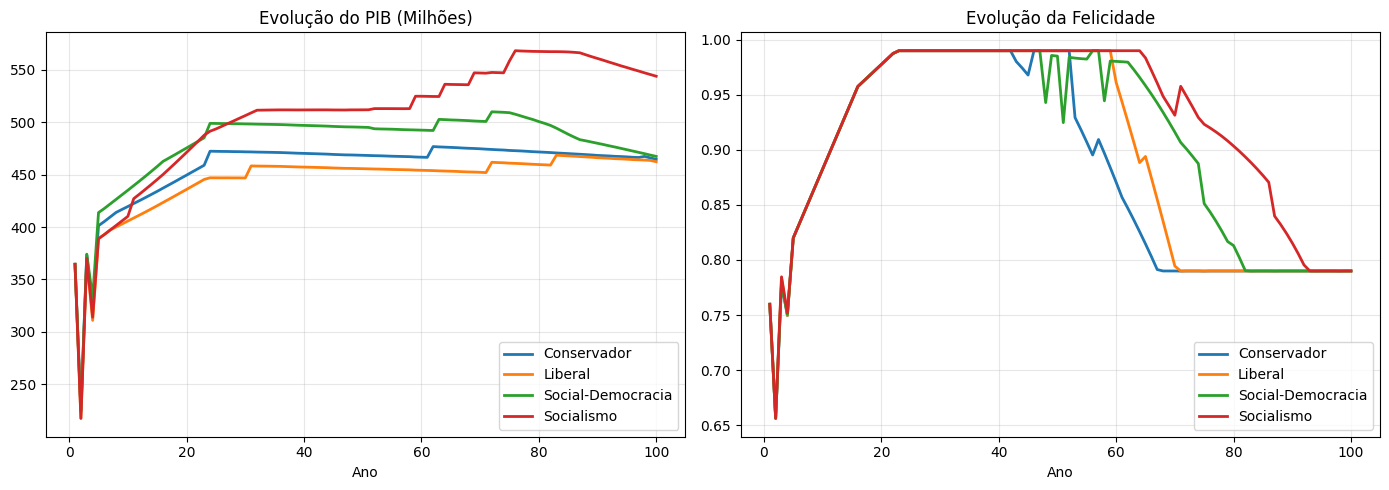

<Figure size 640x480 with 0 Axes>

In [76]:
# Executar o simulador completo
%run main.py